Homework 3 with Pandas

In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\A02047803\Desktop\DATA_5500_FA_26\hw3\TSLA_Full.csv")
df

,Date,Close/Last,Volume,Open,High,Low
0,10/14/2026,$367.16,31001420,$371.16,$371.39,$363.82
1,10/13/2026,$375.23,18393040,$372.325,$377.05,$371.30
2,10/12/2026,$378.03,20244290,$382.605,$382.70,$377.58
3,10/09/2026,$382.70,38952430,$382.38,$388.56,$379.71
4,10/08/2026,$375.00,28394950,$374.12,$375.96,$368.0301
...,...,...,...,...,...,...
246,10/21/2025,$442.60,54412170,$445.755,$449.30,$442.05
247,10/20/2025,$447.43,63718970,$443.865,$449.80,$440.61
248,10/17/2025,$439.31,89331580,$425.50,$441.4558,$423.60
249,10/16/2025,$428.75,77189890,$434.73,$439.35,$421.3101


In [2]:
df = df.iloc[::-1].reset_index(drop=True)
df

,Date,Close/Last,Volume,Open,High,Low
0,10/15/2025,$435.15,71558190,$434.90,$440.51,$426.3301
1,10/16/2025,$428.75,77189890,$434.73,$439.35,$421.3101
2,10/17/2025,$439.31,89331580,$425.50,$441.4558,$423.60
3,10/20/2025,$447.43,63718970,$443.865,$449.80,$440.61
4,10/21/2025,$442.60,54412170,$445.755,$449.30,$442.05
...,...,...,...,...,...,...
246,10/08/2026,$375.00,28394950,$374.12,$375.96,$368.0301
247,10/09/2026,$382.70,38952430,$382.38,$388.56,$379.71
248,10/12/2026,$378.03,20244290,$382.605,$382.70,$377.58
249,10/13/2026,$375.23,18393040,$372.325,$377.05,$371.30


In [7]:
df["Close/Last"] = df["Close/Last"].replace("[$]", "", regex=True).astype(float)
df["Moving_avg"] = df["Close/Last"].shift(1).rolling(window=5).mean()

# create two new columns
df["Buy_Threshold"] = df["Moving_avg"] * 0.98
df["Sell_Threshold"] = df["Moving_avg"] * 1.02
df.head(10)

,Date,Close/Last,Volume,Open,High,Low,Moving_avg,Buy_Threshold,Sell_Threshold
0,10/15/2025,435.15,71558190,$434.90,$440.51,$426.3301,NaN,NaN,NaN
1,10/16/2025,428.75,77189890,$434.73,$439.35,$421.3101,NaN,NaN,NaN
2,10/17/2025,439.31,89331580,$425.50,$441.4558,$423.60,NaN,NaN,NaN
3,10/20/2025,447.43,63718970,$443.865,$449.80,$440.61,NaN,NaN,NaN
4,10/21/2025,442.60,54412170,$445.755,$449.30,$442.05,NaN,NaN,NaN
5,10/22/2025,438.97,84023460,$443.45,$445.539,$429.00,438.648,429.87504,447.42096
6,10/23/2025,448.98,126709800,$420.00,$449.3999,$413.90,439.412,430.62376,448.20024
7,10/24/2025,433.72,94727770,$446.83,$451.68,$430.17,443.458,434.58884,452.32716
8,10/27/2025,452.42,105867500,$439.98,$460.16,$438.69,442.340,433.49320,451.18680
9,10/28/2025,460.55,80185670,$454.775,$467.00,$451.60,443.338,434.47124,452.20476


In [8]:
# comparing moving avg 

buy          = 0
first_buy    = 0
total_profit = 0

df["Signal"] = "hold"

for i in range(len(df)):
    current_price   = df.loc[i, "Close/Last"]
    moving_avg      = df.loc[i, "Moving_avg"]

    if current_price < (moving_avg  * 0.98) and buy == 0: #0.98 for 21 # 0.96 for 22
            print("buying at: ", "\t", round(current_price, 3), "iteration", i)
            buy = current_price
            df.loc[i, "Signal"] = "buy"
            if first_buy == 0:
                first_buy = buy
    elif current_price > (moving_avg * 1.02) and buy != 0: #1.02 for 21 #1.04 for 22
        print("selling at: ", "\t", round(current_price, 3))
        trade_profit = current_price - buy
        df.loc[i, "Signal"] = "sell"
        print("trade profit: ", "\t", round(trade_profit, 2))
        total_profit += trade_profit
        buy = 0
    else:
        df.loc[i, "Signal"] = "hold"
        

buying at:  	 433.72 iteration 7
selling at:  	 452.42
trade profit:  	 18.7
buying at:  	 440.1 iteration 11
selling at:  	 468.37
trade profit:  	 28.27
buying at:  	 444.26 iteration 14
selling at:  	 417.78
trade profit:  	 -26.48
buying at:  	 459.64 iteration 51
selling at:  	 448.96
trade profit:  	 -10.68
buying at:  	 419.25 iteration 65
selling at:  	 449.36
trade profit:  	 30.11
buying at:  	 416.56 iteration 72
selling at:  	 425.21
trade profit:  	 8.65
buying at:  	 410.63 iteration 84
selling at:  	 417.4
trade profit:  	 6.77
buying at:  	 392.43 iteration 94
selling at:  	 381.26
trade profit:  	 -11.17
buying at:  	 360.59 iteration 116
selling at:  	 364.2
trade profit:  	 3.61
buying at:  	 373.72 iteration 130
selling at:  	 390.82
trade profit:  	 17.1
buying at:  	 422.24 iteration 146
selling at:  	 426.01
trade profit:  	 3.77
buying at:  	 415.88 iteration 156
selling at:  	 406.43
trade profit:  	 -9.45
buying at:  	 381.61 iteration 171
selling at:  	 411.8

In [9]:
df

,Date,Close/Last,Volume,Open,High,Low,Moving_avg,Buy_Threshold,Sell_Threshold,Signal
0,10/15/2025,435.15,71558190,$434.90,$440.51,$426.3301,NaN,NaN,NaN,hold
1,10/16/2025,428.75,77189890,$434.73,$439.35,$421.3101,NaN,NaN,NaN,hold
2,10/17/2025,439.31,89331580,$425.50,$441.4558,$423.60,NaN,NaN,NaN,hold
3,10/20/2025,447.43,63718970,$443.865,$449.80,$440.61,NaN,NaN,NaN,hold
4,10/21/2025,442.60,54412170,$445.755,$449.30,$442.05,NaN,NaN,NaN,hold
...,...,...,...,...,...,...,...,...,...,...
246,10/08/2026,375.00,28394950,$374.12,$375.96,$368.0301,372.384,364.93632,379.83168,hold
247,10/09/2026,382.70,38952430,$382.38,$388.56,$379.71,376.562,369.03076,384.09324,hold
248,10/12/2026,378.03,20244290,$382.605,$382.70,$377.58,378.984,371.40432,386.56368,hold
249,10/13/2026,375.23,18393040,$372.325,$377.05,$371.30,378.844,371.26712,386.42088,hold


In [10]:
final_profit_percentage = ( total_profit / first_buy ) * 100    

print("-----------------------")
print("Total profit: ", "\t", round(total_profit, 2))
print("First buy: ", "\t", first_buy)
print("% return: ", "\t", round(final_profit_percentage, 2))

-----------------------
Total profit:  	 66.79
First buy:  	 433.72
% return:  	 15.4


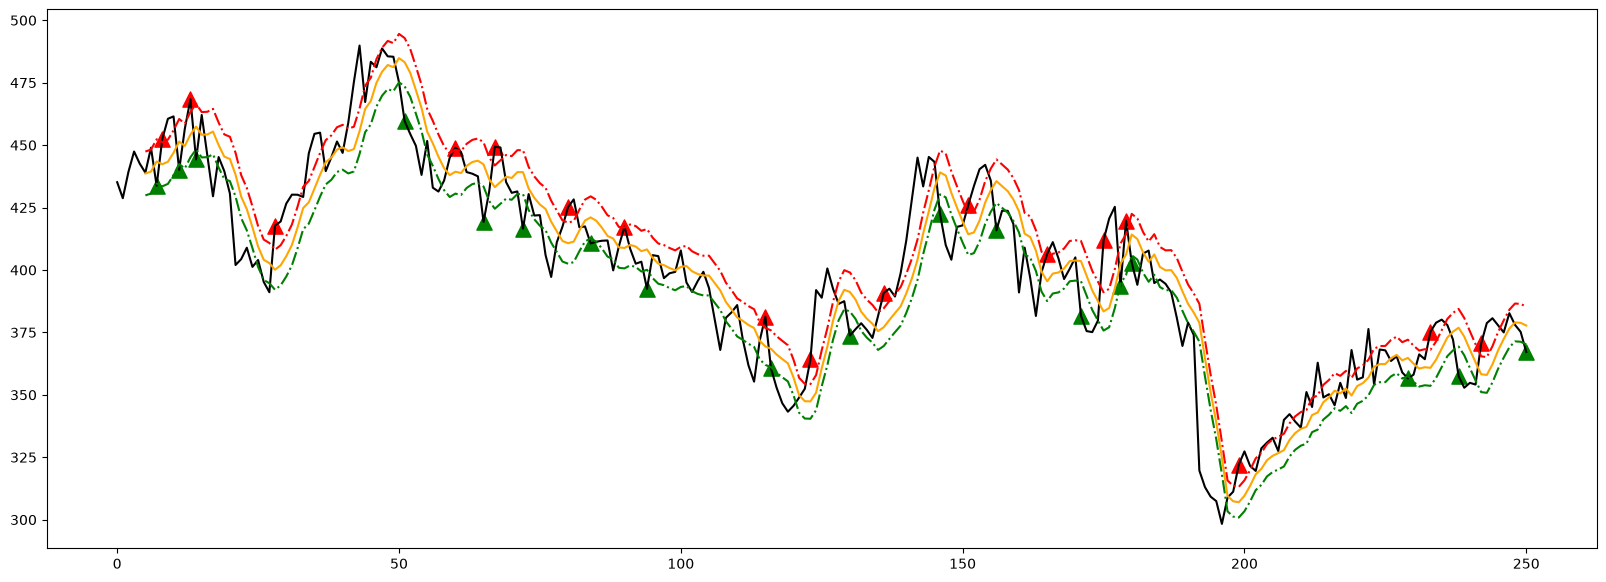

In [ ]:
# plot it
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 7))

# price
plt.plot(
    df.index,
    df["Close/Last"],
    label="TSLA Price",
    color="black"
)

# moving avg
plt.plot(
    df.index,
    df["Moving_avg"],
    label="Moving Average",
    color="orange"
)

# buy signal line
plt.plot(
    df.index,
    df["Buy_Threshold"],
    label="Buy Threshold",
    color="green",
    linestyle="-."
)

# sell signal line
plt.plot(
    df.index,
    df["Sell_Threshold"],
    label="Sell Threshold",
    color="red",
    linestyle="-."
)

# plot the buys and sells
buys = df[df["Signal"] == "buy"]
sells = df[df["Signal"] == "sell"]

plt.scatter(
    buys.index,
    buys["Close/Last"],
    marker="^",
    color="green",
    s=120,
    label="buy signal"
)

plt.scatter(
    sells.index,
    sells["Close/Last"],
    marker="^",
    color="red",
    s=120,
    label="sell signal"
)


plt.show()